# How the PBBM robot librarian shelves a book

This notebook takes apart [PBBM-robot-librarian](https://github.com/TAMS-Group/PBBM-robot-librarian)
(cloned into `PBBM-robot-librarian/`) and explains, step by step, how it got a real **PR2 robot** to take a
book off a shelf and put it back in a chosen place.

None of their code runs here. It is ROS Noetic + MoveIt + a GPU, wired to a physical PR2. Instead, every
section quotes the file that does the step, and where the idea is just maths (matching a spine to the
database, fusing observations over time, planning where books go) it is **re-implemented in a few lines
of numpy** so you can run it and poke at it. The last section re-enacts their placing trick in our MuJoCo
simulator.

**Contents**
1. The hardware and the software map
2. The book database
3. Vision, part 1: finding spines and text (YOLOv5, CRAFT, DTRB)
4. Vision, part 2: which book is this spine? (runnable)
5. Vision, part 3: one belief from many noisy frames (runnable)
6. Deciding what to do: `interaction_node.py` (runnable)
7. Manipulation, picking: tilt, grasp, extract
8. Manipulation, placing: lean it, then push it upright
9. Why it worked, and what it never had to do
10. What carries over to our MuJoCo project, plus a MuJoCo re-enactment of their placing trick

In [1]:
import csv, os, sys
import numpy as np
import matplotlib.pyplot as plt
import mediapy

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
PBBM = os.path.join(ROOT, "PBBM-robot-librarian")
LIB = os.path.join(PBBM, "librarian_common", "librarian_resources")
print("PBBM repo found:", os.path.isdir(PBBM))

PBBM repo found: True


## 1. The hardware and the software map

**Robot.** A PR2 (a two-armed mobile robot with a torso that moves up and down). The **left arm** has the
standard PR2 parallel gripper with a force/torque sensor (`/ft/l_gripper_motor`). The **right arm** has a
**Shadow Dexterous Hand** with BioTac fingertip sensors. An **Azure Kinect** RGB-D camera looks at the
shelf. **AprilTags** (printed fiducial markers) on the shelf give its pose.

**Software.** Three ROS packages, talking over ROS topics and services:

```
 Azure Kinect ──RGB + point cloud──►  librarian_vision                               librarian_manipulation
                                     ┌────────────────────────────────────┐          ┌──────────────────────────┐
 AprilTags ──► shelf corners (tf) ──►│ 1 librarian_image_preproc.py       │          │ grasping_controller.py   │
                                     │   rectify each shelf level         │          │  pick():  Shadow Hand    │
                                     │ 2 detection_node.py                │          │           tilts the book,│
                                     │   YOLOv5 spines + CRAFT text boxes │          │           gripper grasps │
                                     │ 3 recognize_node.py                │          │  place(): lean it on a   │
                                     │   DTRB (or Google) OCR             │          │           neighbour, push│
                                     │ 4 librarian_book_extract.py        │          │           it upright     │
                                     │   3-D pose (point cloud) + match   │          │  (MoveIt + bio_ik +      │
                                     │   to books.csv                     │          │   force thresholds)      │
                                     │ 5 librarian_environment.py         │          └────────────▲─────────────┘
                                     │   k-means over 10 frames → belief  │                       │ ManipulationService
                                     └───────────────┬────────────────────┘                       │ (book, place pose,
                                                     │ /librarian/environment                     │  approach side)
                                                     ▼                                            │
                                     librarian_common/.../interaction_node.py  ───────────────────┘
                                       waits for "r" / "y" / "w" / "sort" on /chatter,
                                       sorts the believed books, sends one manipulation request per book
```

The belief also goes into the **MoveIt planning scene** as box collision objects (one per book, sized
from the database). That is how the arm planners know where the books are.

## 2. The book database

Everything downstream leans on a **known, closed set of books**: `librarian_resources/books.csv` (15
books) plus one photo of each spine, `spines/id_<N>.png`. Perception only ever has to answer "which of
these 15 is it?". It never has to read an unknown title.

> **Column-name trap.** In `books.csv`, `depth` is the thickness across the spine (2-4.5 cm) and `width` is
> front-to-back. In our `shelf_scene.Book`, `thickness` is across the spine and `depth` is front-to-back.

In [2]:
DB = {int(r["id"]): r for r in csv.DictReader(open(os.path.join(LIB, "books.csv"), encoding="utf-8"))}
print(f"{'id':>2}  {'title':<48} {'h':>6} {'spine':>6} {'front-back':>10} {'kg':>5}")
for i, r in DB.items():
    print(f"{i:>2}  {r['title'][:48]:<48} {float(r['height']):6.3f} {float(r['depth']):6.3f} {float(r['width']):10.3f} {float(r['weight']):5.2f}")

id  title                                                 h  spine front-back    kg
 1  LINKAGE AND DEVELOPING COUNTRIES Volume III       0.225  0.023      0.150  0.82
 2  Künstliche Intelligenz Überblick und Grundlagen   0.190  0.011      0.125  0.21
 3  Elektronische Halbleiterbauelemente               0.186  0.026      0.126  0.50
 4  LOGIC DESIGN AND SIMULATION Volume 2              0.245  0.018      0.173  0.62
 5  GUI & Visualization Services Volume III           0.212  0.033      0.174  0.95
 6  THE TTL Data Book Volume 2                        0.207  0.045      0.149  1.36
 7  Requirements-Engineering und-Management           0.243  0.029      0.175  0.95
 8  Betriebliche Expertensystem-Anwendungen           0.246  0.032      0.173  0.84
 9  Graphik in Industrie und Technik                  0.247  0.025      0.173  1.01
10  CAE-gestützte IC-Entwurfs-methoden                0.243  0.045      0.179  1.42
11  Innovations-management                            0.228  0.040      0.14

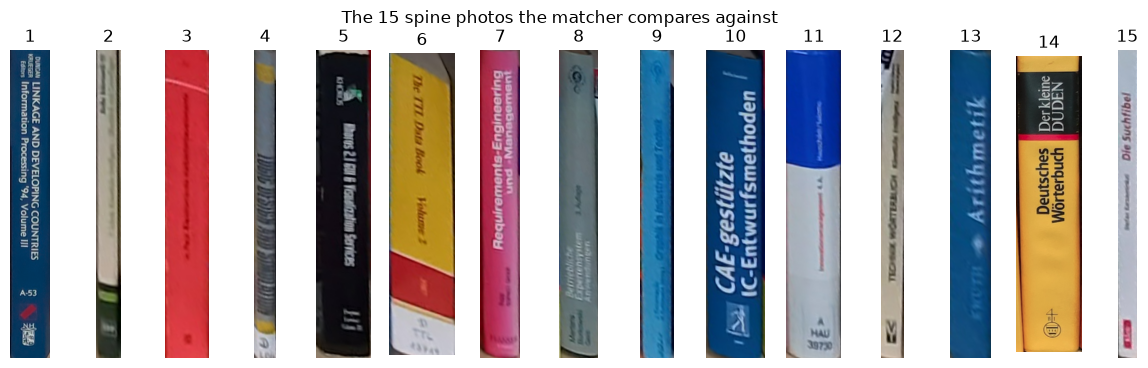

In [3]:
spines = {i: mediapy.read_image(os.path.join(LIB, "spines", f"id_{i}.png"))[..., :3] for i in DB}
fig, axes = plt.subplots(1, len(spines), figsize=(15, 4))
for ax, (i, img) in zip(axes, spines.items()):
    ax.imshow(img); ax.set_title(str(i)); ax.axis("off")
plt.suptitle("The 15 spine photos the matcher compares against"); plt.show()

## 3. Vision, part 1: finding spines and text

These steps need network weights that are not in the repo, so they are described here rather than run.

| Step | File | What it does |
|---|---|---|
| Rectify | `librarian_vision_node/scripts/librarian_image_preproc.py` | Uses the shelf corners (from AprilTags, `librarian_shelf_from_image.py`) to apply a **perspective warp** to each of the two shelf levels, so spines stand straight up in the image. YOLO's boxes are axis-aligned, so straight spines give tight boxes. |
| Detect | `detection_node.py` | A **fine-tuned YOLOv5** finds spine boxes. **CRAFT** finds text regions. Boxes are mapped back to the original image. |
| Read | `recognize_node.py` | **DTRB** (TPS-ResNet-BiLSTM-Attn) or the Google Cloud Vision API reads each text region. |
| 3-D | `librarian_book_extract.py` + `librarian_pc_process_node.cpp` | Averages the point-cloud points inside each spine polygon to get the spine's 3-D position, and measures its size in metres. |

**Takeaway for us:** in simulation, MuJoCo's **segmentation rendering** gives exact spine masks for free
(notebook 01 uses it), so YOLO is only needed later for sim-to-real.

## 4. Vision, part 2: which book is this spine?

`librarian_book_extract.py → match_books()` builds a **score matrix**: one row per detected spine, one
column per database book. It computes several features (fuzzy title match on the OCR text, hue /
saturation / value histogram cosine similarity, aspect ratio, area, SIFT matches, and a **CLIP image
embedding** of the spine crop). In the version in the repo, only the CLIP score is used:
`scores.append(enc_scores)`. The other lines are commented out.

It then assigns IDs **greedily**: take the highest score in the whole matrix, give that spine that book,
delete that row and column, and repeat. Each book can then be used only once.

Below, the same algorithm runs with the hue/saturation histogram feature (CLIP would need `torch` +
`transformers`). Each "detection" is a database photo that has been cropped, darkened and made noisy,
the way a camera frame differs from the reference photo.

argmax per spine : 4 / 8 correct
greedy, unique   : 3 / 8 correct


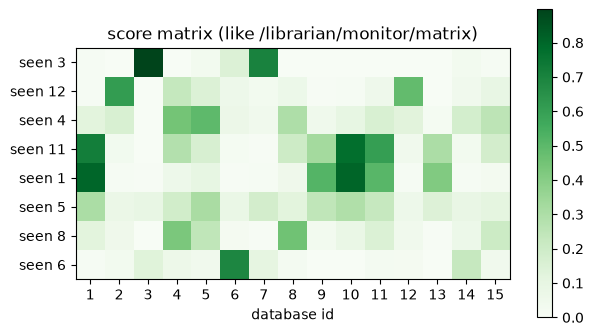

In [4]:
def hs_hist(rgb, bins=16):
    # 2-D hue x saturation histogram, unit length (cosine similarity = dot product)
    x = rgb.reshape(-1, 3).astype(float) / 255
    mx, mn = x.max(1), x.min(1); c = mx - mn + 1e-9
    r, g, b = x.T
    h = np.where(mx == r, (g - b) / c % 6, np.where(mx == g, (b - r) / c + 2, (r - g) / c + 4)) / 6
    s = (mx - mn) / (mx + 1e-9)
    hist = np.histogram2d(h, s, bins=bins, range=[[0, 1], [0, 1]])[0].ravel()
    return hist / (np.linalg.norm(hist) + 1e-9)

def camera_view(img, rng, crop=0.8, light=(0.5, 1.2), noise=10):
    # what a detector crop might look like: partly cut off, differently lit, noisy
    H, W = img.shape[:2]
    h, w = int(H * rng.uniform(crop, 1)), int(W * rng.uniform(crop, 1))
    y, x = rng.integers(0, H - h + 1), rng.integers(0, W - w + 1)
    out = img[y:y + h, x:x + w] * rng.uniform(*light) + rng.normal(0, noise, (h, w, 3))
    return np.clip(out, 0, 255).astype(np.uint8)

def greedy_assign(S):
    # PBBM's assignment: repeatedly take the best remaining (detection, book) pair
    S = S.astype(float).copy(); out = {}
    for _ in range(min(S.shape)):
        r, c = np.unravel_index(np.argmax(S), S.shape)
        out[int(r)] = int(c); S[r, :] = -np.inf; S[:, c] = -np.inf
    return out

ids = sorted(DB)
DB_HIST = np.array([hs_hist(spines[i]) for i in ids])
rng = np.random.default_rng(0)
truth = rng.permutation(ids)[:8]                     # 8 books seen on the shelf
S = np.array([DB_HIST @ hs_hist(camera_view(spines[i], rng)) for i in truth])
greedy = greedy_assign(S)
print("argmax per spine :", sum(ids[int(np.argmax(S[k]))] == t for k, t in enumerate(truth)), "/ 8 correct")
print("greedy, unique   :", sum(ids[greedy[k]] == t for k, t in enumerate(truth)), "/ 8 correct")

plt.figure(figsize=(7, 4)); plt.imshow(S, cmap="Greens")
plt.yticks(range(8), [f"seen {t}" for t in truth]); plt.xticks(range(15), ids)
plt.xlabel("database id"); plt.title("score matrix (like /librarian/monitor/matrix)"); plt.colorbar(); plt.show()

Greedy isn't always better than taking each spine's best match. Greedy forbids duplicates, but one confident
wrong pick early on takes a book away from the spine it really belongs to. Run the cell with other seeds. Colour alone confuses books with similar covers, which is why
PBBM tried text, SIFT and CLIP as well. In the repo, `librarian_vision/results/` holds their evaluation
labels, but not the predictions they were scored against, so we can't recompute their accuracy here.

## 5. Vision, part 3: one belief from many noisy frames

One frame is unreliable, so `librarian_environment.py` waits for **10 frames** (`num_samples = 10`), then:

1. pools every detection's 3-D position and runs **k-means**, with k = the largest number of books seen in any
   one frame;
2. drops clusters with fewer than **4** detections (`cluster_threshold = 4`), which are probably false
   positives;
3. gives each cluster the ID it was most often matched to, **greedily** and uniquely, as in section 4;
4. averages position and size within each cluster and publishes the result as `/librarian/environment`. It
   also writes the books into the MoveIt planning scene.

This is a hand-built **belief state**, the core idea of a POMDP. Below it runs on simulated frames.

In [5]:
def kmeans(X, k, rng, iters=50):
    C = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        lab = np.argmin(((X[:, None] - C[None]) ** 2).sum(-1), 1)
        C = np.array([X[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])
    return lab

rng = np.random.default_rng(1)
shelf = rng.permutation(ids)[:6]                          # 6 books, left to right
xs = np.cumsum([float(DB[i]["depth"]) + 0.005 for i in shelf])
frames = []                                               # (x, matched id) for each detection in each frame
for f in range(10):
    seen = [k for k in range(6) if rng.random() < 0.85]   # some spines are missed in some frames
    S = np.array([DB_HIST @ hs_hist(camera_view(spines[shelf[k]], rng)) for k in seen])
    match = greedy_assign(S)
    frames.append([(xs[k] + rng.normal(0, 0.004), ids[match[n]]) for n, k in enumerate(seen)])

single = np.mean([np.mean([i == shelf[np.argmin(abs(xs - x))] for x, i in fr]) for fr in frames])
X = np.array([[x] for fr in frames for x, _ in fr]); obs_ids = [i for fr in frames for _, i in fr]
lab = kmeans(X, max(len(fr) for fr in frames), rng)
votes = [dict() for _ in range(lab.max() + 1)]
for l, i in zip(lab, obs_ids):
    votes[l][i] = votes[l].get(i, 0) + 1
keep = [c for c in range(len(votes)) if sum(votes[c].values()) >= 4]
belief = {}
while keep:                                               # greedy unique id per cluster
    c = max(keep, key=lambda c: max(votes[c].values(), default=-1))
    if not votes[c]: break
    best = max(votes[c], key=votes[c].get); belief[c] = best; keep.remove(c)
    for o in keep: votes[o].pop(best, None)
fused = np.mean([belief[c] == shelf[np.argmin(abs(xs - X[lab == c].mean()))] for c in belief])
print(f"single-frame id accuracy: {single:.0%}   after fusing 10 frames: {fused:.0%}  ({len(belief)} books in the belief)")

single-frame id accuracy: 33%   after fusing 10 frames: 50%  (6 books in the belief)


## 6. Deciding what to do: `interaction_node.py`

The "brain" is a small script, `librarian_common/librarian_resources/scripts/interaction_node.py`. It waits for
a string on the `/chatter` topic:

- `sort` → `sort_books()`: take the believed books, **sort by height, tallest first, then skip the tallest**
  (`books_ordered[1:]`), and place them one by one on the **lower shelf from the left end**. The place
  pose is given in the frame `shelf_0_0_0` as the book's lowest, shallowest corner, at
  `x = cm_counter`, with `cm_counter += book thickness` after each book.
- `r`, `y`, `w` (the red, yellow and white books in their demo): move one book. As configured, only **`r` does a
  full pick-and-place**. `y` and `w` run `pick_data` (pick only), as the README says.

There is no search and no learning, just a fixed recipe. It works because the lower shelf is **empty on the
left**, so there is always room. Below is the same plan computed for a random set of books:

In [6]:
upper_shelf = [DB[i] for i in rng.permutation(ids)[:5]]
ordered = sorted(upper_shelf, key=lambda r: float(r["height"]), reverse=True)[1:]
cm = 0.0
print("place on lower shelf (frame shelf_0_0_0), approach from the right:")
for r in ordered:
    print(f"  x = {cm:5.3f} m   '{r['title'][:40]}'  (h {float(r['height']):.3f}, spine {float(r['depth']):.3f})")
    cm += float(r["depth"])
print("skipped (tallest):", sorted(upper_shelf, key=lambda r: float(r["height"]))[-1]["title"])

place on lower shelf (frame shelf_0_0_0), approach from the right:
  x = 0.000 m   'Innovations-management'  (h 0.228, spine 0.040)
  x = 0.040 m   'LINKAGE AND DEVELOPING COUNTRIES Volume '  (h 0.225, spine 0.023)
  x = 0.062 m   'GUI & Visualization Services Volume III'  (h 0.212, spine 0.033)
  x = 0.096 m   'Künstliche Intelligenz Überblick und Gru'  (h 0.190, spine 0.011)
skipped (tallest): Betriebliche Expertensystem-Anwendungen


## 7. Manipulation, picking: tilt, grasp, extract

`grasping_controller.py → pick()`, built from `SHInterface.tilt_book` (Shadow Hand) and
`GripperInterface.grasp_book` / `extract_book_regrasp` (gripper). On a full shelf a book can't be grabbed from
the sides, so they use **two hands**:

| # | Who | Motion (from the code) |
|---|---|---|
| 3.1 | torso | raise to the shelf the book is on (z > 0.948 m → upper shelf) |
| 3.2 | Shadow Hand | fingers flat, hand in front of the book, first finger **above the book's top**, down 3 cm, then 2.5 cm more to press on it, then pull back 5 cm in a straight line, so the book **tilts out** about its bottom back edge |
| 3.3 | gripper | go in front of the now-exposed top corner, straight in, close |
| 3.4 | both | hand lifts off and moves away. Gripper pulls back a bit, **opens so the book falls back upright** with more of the spine showing, moves forward, **re-grasps**, pulls it all the way out |
| 4 | gripper | hold the book in front of the camera (meant for checking the cover; not used) |

Each motion goes through MoveIt (Cartesian straight lines, or `bio_ik` for goal poses). In MoveIt the book is
an attached collision object, and collision checking between book and fingertip is switched off just
for the pressing step (this needs their **modified MoveIt** fork).

## 8. Manipulation, placing: lean it, then push it upright

`GripperInterface.place_book_vertical` and `push_book_upright`. This is the clever part. Instead of
lowering a book precisely into a gap, they let the shelf do the aligning, using **guarded moves**: move
until the wrist force sensor feels contact.

```
   step 5.2: place leaning                      step 5.3: push upright
   ───────────────────────                      ───────────────────────
   hold the book rolled 0.38 rad (~22°)          gripper turned 90°, beside the book
   move in 'book depth + 10 cm'                  move in
   move sideways until  ΔFx > 2 N  ─┐            move sideways until  ΔFy > 4 N
   move down until      ΔFy > 2 N   │  wall /       (the book swings upright against
   open, back off 12 cm             │  previous     the neighbour / wall)
        ╲                           │  book         back off, open
         ╲  ← book now leans on ────┘
          ╲    its neighbour
```

- No gap needs to be measured accurately. The book only has to be **somewhere beside** the neighbour or
  wall, and the force threshold finds the contact.
- In `--demo` (no real robot) the force moves become fixed distances (`move_right(0.07)`, `move_upward(-0.06)`).
- Errors don't trigger automatic recovery. `__report_error` **asks the operator** at the terminal: `q` quit,
  `r` retry the step, `c` skip it, or give a step number to jump to.

## 9. Why it worked, and what it never had to do

The README and code show a lot of **structure engineered into the setup**:

- **Fixed geometry.** The shelf is moved by hand until its AprilTag frame matches a given pose. Books are put in the
  upper shelf "largest to smallest from left to right". The torso heights for the two shelves are hard-coded, and
  so is the 0.948 m threshold between them.
- **Known books.** There are 15 known books with exact measurements. Their MoveIt collision boxes come from the
  database, not from perception.
- **Free space to place into.** Books go to the empty left end of the lower shelf. They never create a gap, shift a
  neighbour, or fix a leaning book.
- **A human in the loop** for failures, and for clearing a stale attached book in RViz (README, Figure 1).
- **Two arms with a dexterous hand** for the tilt-out pick.
- **No learning in the control loop.** The learned parts are perception only (YOLOv5, CRAFT, DTRB, CLIP).

So the answer to "how did it succeed?" is: **a modular pipeline (perceive → believe → decide → scripted
guarded motions) in a structured scene**. That is the honest baseline any RL system should beat, or match with
less structure.

## 10. What carries over to our MuJoCo project

| PBBM piece | Port it? | How in our repo |
|---|---|---|
| `books.csv` + `spines/*.png` | **Yes, directly** | Textures on the spine face of our books. Notebook 01 does this. |
| Per-level rectification, YOLO, CRAFT, DTRB | Later, for sim-to-real | Sim gives segmentation masks for free. The networks can be run on rendered images if wanted. |
| Score matrix + greedy unique assignment | **Yes** | Notebook 01 §4 uses it on rendered spines. |
| 10-frame k-means belief | **Yes, as the idea** | Becomes the belief state of the POMDP (a filter, or a recurrent policy). |
| `interaction_node` sort recipe | **Yes, as the high-level baseline** | Slot choice from sorted titles (notebook 01 §5). |
| Tilt-out pick with Shadow Hand | No | We have one Panda with a parallel gripper. Our task starts with the book in hand. |
| Lean-then-push-upright place | **Yes, as an idea** | Our `leaning` scenario + `insert_book.Episode.stand_up` is the same physics. See below. |
| ROS / MoveIt / bio_ik / PR2 | No | Replaced by MuJoCo + `insert_book.ArmIK` (differential IK) + position actuators. |

### Re-enacting the placing trick in MuJoCo

The `leaning` scenario puts a book at rest leaning on its neighbour, like PBBM's step 5.2. Our scripted
`insert_leaning` then stands it up, as in PBBM's step 5.3, and inserts the target book.
This takes ~10 s to run.

neighbour tilts (deg) before: [22.6, 0.0]  after: [0.0, 0.0]
  SUCCESS [lift the leaner, then none needed]: tilt 0.0 deg, spine +0.3 mm from the neighbour's, released
  other books: most moved 0.1 mm (all together 0 mm), most tilted 0.0 deg | let go after 13.1 s, in place after 18.7 s


leaning neighbour (PBBM step 5.2),stood up + book inserted (5.3 + insert)

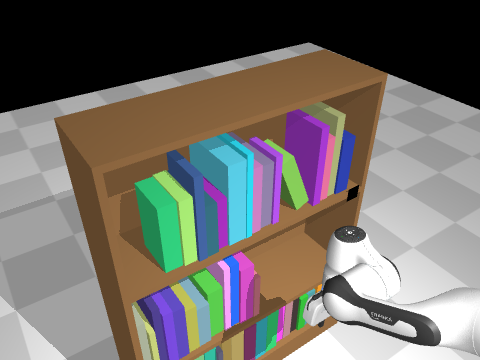
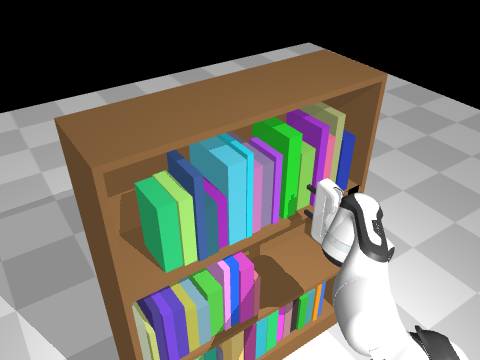

In [7]:
import mujoco
from insert_book import Episode, make_episode, report, DEFAULT_PANDA
from shelf_scene import ShelfConfig, book_tilt_deg

def render(model, data, camera="scene_cam", size=(360, 480)):
    with mujoco.Renderer(model, *size) as r:
        r.update_scene(data, camera=camera)
        return r.render()

model, data, row = make_episode(ShelfConfig(), "leaning", np.random.default_rng(0), DEFAULT_PANDA)
ti = row.target_index
lean = lambda: [round(book_tilt_deg(data.xquat[model.body(row.books[i].name).id]), 1) for i in (ti - 1, ti)]
before = render(model, data); lean_before = lean()
res = Episode(model, data, row, None, log=lambda *a: None).insert_leaning()
print("neighbour tilts (deg) before:", lean_before, " after:", lean())
print(report(res))
mediapy.show_images([before, render(model, data)], titles=["leaning neighbour (PBBM step 5.2)", "stood up + book inserted (5.3 + insert)"])

**Next:** `01_mujoco_librarian_pomdp.ipynb` builds the whole flow in MuJoCo (labels → belief → slot →
adjustment → insertion), writes it as a POMDP, and sets up the environment an RL agent would train in.